In [1]:
%pip -q install "qiskit==2.2.3" "qiskit-algorithms==0.4.0" "qiskit-optimization==0.7.0" "qiskit-machine-learning==0.9.0" "koreanize-matplotlib==0.1.1"

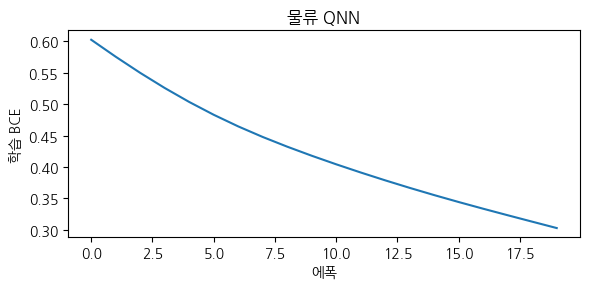

후보별 평균 거리와 혼잡도:
 [[13.38333352  0.5       ]
 [14.19999981  0.6       ]
 [14.66666683  0.6       ]
 [14.33333317  0.54999999]
 [14.08333317  0.55      ]]
후보별 비용: [15.88333352 17.19999982 17.66666681 17.08333314 16.83333318]

========== 최종 결과 ==========
QAOA 후보: ['A']
VQE 후보: ['A']


In [11]:
import numpy as np
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from itertools import product
import matplotlib.pyplot as plt
import koreanize_matplotlib

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import real_amplitudes
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit.primitives import StatevectorEstimator, StatevectorSampler

from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import COBYLA as VCOBYLA

from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.connectors import TorchConnector

from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import QuadraticProgramToQubo
from qiskit_optimization.minimum_eigensolvers import QAOA
from qiskit_optimization.optimizers import COBYLA
from qiskit_optimization.algorithms import MinimumEigenOptimizer


# ----------------------------------------------------
# 1) QNN 분류기 함수 정의
# ----------------------------------------------------
def train_classifier(features, labels, title, split=None):
    torch.manual_seed(42)
    indices = np.arange(len(labels))
    train, test = (train_test_split(indices, test_size=0.3, stratify=labels, random_state=42)
                   if split is None else split)
    low, width = features[train].min(axis=0), np.ptp(features[train], axis=0)
    normalized = np.clip((features-low)/np.where(width>0, width, 1), 0, 1)
    X = torch.tensor(0.05+0.9*normalized, dtype=torch.float32)
    y = torch.tensor(labels[:, None], dtype=torch.float32)

    inputs, weights = ParameterVector('x', 2), ParameterVector('theta', 8)
    circuit = QuantumCircuit(2)
    for j in range(2): circuit.ry(np.pi*inputs[j], j)
    for layer in range(2):
        circuit.cx(layer%2, 1-layer%2)
        for j in range(2):
            circuit.ry(weights[4*layer+2*j], j)
            circuit.rz(weights[4*layer+2*j+1], j)

    observables = [SparsePauliOp.from_list([(name, 1)]) for name in ['ZI','IZ','ZZ']]
    qnn = EstimatorQNN(circuit=circuit, estimator=StatevectorEstimator(),
        observables=observables, input_params=list(inputs), weight_params=list(weights),
        default_precision=0.0, input_gradients=True)

    model = nn.Sequential(TorchConnector(qnn, initial_weights=np.linspace(-0.3, 0.3, 8)),
                          nn.Linear(3, 1))
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.03, weight_decay=0.01)
    loss_fn = nn.BCEWithLogitsLoss()
    history = []

    for epoch in range(20):  # 속도를 위해 20에폭으로 설정
        optimizer.zero_grad()
        logits = model(X[train]); loss = loss_fn(logits, y[train])
        loss.backward(); optimizer.step(); history.append(float(loss.detach()))

    with torch.no_grad():
        probabilities = torch.sigmoid(model(X))

    plt.figure(figsize=(6, 3)); plt.plot(history)
    plt.title(title); plt.xlabel('에폭'); plt.ylabel('학습 BCE')
    plt.tight_layout(); plt.show(); plt.close()
    return probabilities.numpy().ravel()


# ----------------------------------------------------
# 2) VQE 함수 정의
# ----------------------------------------------------
def run_vqe(problem, title, seed=42):
    converter = QuadraticProgramToQubo()
    qubo = converter.convert(problem)
    H, offset = qubo.to_ising()
    n = qubo.get_num_vars()

    ansatz = real_amplitudes(n, reps=2, entanglement="linear")
    vqe = VQE(
        StatevectorEstimator(),
        ansatz,
        VCOBYLA(maxiter=40),
        initial_point=np.random.default_rng(seed).uniform(-1, 1, ansatz.num_parameters)
    )
    result = vqe.compute_minimum_eigenvalue(H)
    state = Statevector.from_instruction(ansatz.assign_parameters(result.optimal_parameters))
    probabilities = state.probabilities()

    candidates = []
    for i, p in enumerate(probabilities):
        bits = np.array([(i >> j) & 1 for j in range(n)])
        x = np.asarray(converter.interpret(bits))
        if problem.is_feasible(x):
            candidates.append((float(p), x))

    probability, chosen = max(candidates, key=lambda item: item[0])
    return {"x": chosen, "fval": float(problem.objective.evaluate(chosen))}


# ----------------------------------------------------
# 3) QAOA 함수 정의
# ----------------------------------------------------
def run_qaoa(problem, title, seed=42):
    qaoa = QAOA(
        StatevectorSampler(default_shots=1024, seed=seed),
        COBYLA(maxiter=30),
        reps=1,
        initial_point=np.random.default_rng(seed).uniform(0.1, 1, 2),
    )
    result = MinimumEigenOptimizer(qaoa).solve(problem)
    return {"x": result.x, "fval": float(result.fval)}


# ----------------------------------------------------
# 4) 메인 실행부 (사용자 작성 코드 연동)
# ----------------------------------------------------
data = np.array([
    [12.3, 0.2, 1], [15.1, 0.8, 0], [10.5, 0.1, 1], [16.2, 0.9, 0],
    [11.4, 0.3, 1], [14.8, 0.7, 0], [13.5, 0.4, 1], [17.3, 1.0, 0],
    [10.8, 0.2, 1], [15.9, 0.9, 0], [11.2, 0.3, 1], [16.5, 0.8, 0],
    [13.0, 0.5, 1], [17.0, 0.9, 0], [12.5, 0.2, 1], [18.2, 1.0, 0],
    [11.8, 0.3, 1], [15.5, 0.7, 0], [10.9, 0.1, 1], [16.9, 0.9, 0],
    [12.1, 0.3, 1], [14.9, 0.7, 0], [13.8, 0.4, 1], [17.4, 0.9, 0],
    [11.0, 0.2, 1], [15.7, 0.8, 0], [12.7, 0.3, 1], [16.4, 0.9, 0],
    [10.7, 0.1, 1], [18.0, 1.0, 0]
], dtype=np.float32)

features, labels = data[:, :2].astype(float), data[:, 2].astype(float)
probabilities = train_classifier(features, labels, '물류 QNN')

# 같은 30행에서 0~5, 6~11, ... 구간을 각각 6회 관측한 후보 A~E로 가정합니다.
routes = features.reshape(5, 6, 2).mean(axis=1)
costs = routes[:, 0] + 5 * routes[:, 1]

print('후보별 평균 거리와 혼잡도:\n', routes)
print('후보별 비용:', costs)

problem = QuadraticProgram()
for name in 'ABCDE':
    problem.binary_var(name)

problem.minimize(linear=costs)
problem.linear_constraint({name: 1 for name in 'ABCDE'}, '==', 1, 'one_route')

qaoa_result = run_qaoa(problem, '물류 QAOA')
vqe_result = run_vqe(problem, '물류 VQE')

print('\n========== 최종 결과 ==========')
print('QAOA 후보:', np.array(list('ABCDE'))[qaoa_result["x"] > 0.5])
print('VQE 후보:', np.array(list('ABCDE'))[vqe_result["x"] > 0.5])
print('===============================')